In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/stats_processed_all_bouts.csv", sep=";")
df["event_date"] = pd.to_datetime(df["event_date"], format="%d/%m/%Y")
df = df.sort_values("event_date").reset_index(drop=True)

print(df.shape)
print(df["event_date"].min().date(), "to", df["event_date"].max().date())
df.head()

Matplotlib is building the font cache; this may take a moment.


(8737, 74)
1994-03-11 00:00:00 2026-06-27 00:00:00


,red_fighter_name,blue_fighter_name,event_date,red_fighter_result,blue_fighter_result,fight_outcome,method,round,time,time_format,...,blue_fighter_stance,blue_fighter_slpm_cs,blue_fighter_str_acc_cs,blue_fighter_sapm_cs,blue_fighter_str_def_cs,blue_fighter_td_avg_cs,blue_fighter_td_acc_cs,blue_fighter_td_def_cs,blue_fighter_sub_avg_cs,winner
0,SCOTT MORRIS,SEAN DAUGHERTY,1994-03-11,W,L,red_win,Submission,1.0,0:20,No Time Limit,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,red
1,FRANK HAMAKER,THADDEUS LUSTER,1994-03-11,W,L,red_win,Submission,1.0,4:52,No Time Limit,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,red
2,JASON DELUCIA,SCOTT BAKER,1994-03-11,W,L,red_win,Submission,1.0,6:41,No Time Limit,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,red
3,JOHNNY RHODES,DAVID LEVICKI,1994-03-11,W,L,red_win,KO/TKO,1.0,12:13,No Time Limit,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,red
4,JOHNNY RHODES,FRED ETTISH,1994-03-11,W,L,red_win,Submission,1.0,3:07,No Time Limit,...,Southpaw,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,red


In [ ]:
df.info()

Always-red accuracy: 0.6407178650506934


In [6]:
print(df["winner"].value_counts(dropna=False))
print(df["fight_outcome"].value_counts())

winner
red     5498
blue    3083
NaN      156
Name: count, dtype: int64
fight_outcome
red_win       5498
blue_win      3083
no_contest      91
draw            65
Name: count, dtype: int64


In [7]:
dec = df[df["winner"].isin(["red", "blue"])]
print("Decisive fights:", len(dec))
print("Always-red accuracy:", round((dec["winner"] == "red").mean(), 4))

Decisive fights: 8581
Always-red accuracy: 0.6407


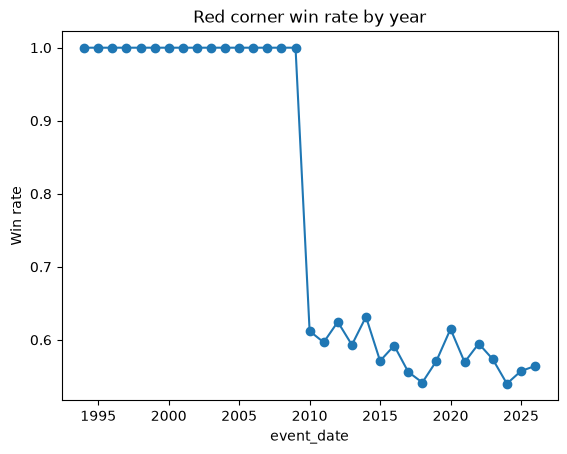

In [8]:
by_year = dec.groupby(dec["event_date"].dt.year)["winner"].apply(lambda s: (s == "red").mean())
by_year.plot(marker="o", title="Red corner win rate by year")
plt.ylabel("Win rate")
plt.show()

In [15]:
pre = dec[dec["event_date"].dt.year < 2010]
post = dec[dec["event_date"].dt.year >= 2010]
print("Pre-2010: ", len(pre), "fights, red wins:", (pre["winner"] == "red").sum(), "| blue wins:", (pre["winner"] == "blue").sum())
print("2010+:    ", len(post), "fights, always-red accuracy:", round((post["winner"] == "red").mean(), 4))

Pre-2010:  1229 fights, red wins: 1229 | blue wins: 0
2010+:     7352 fights, always-red accuracy: 0.5807


In [9]:
print(df["method"].value_counts().head(8))
print(df["bout_type"].value_counts().head(10))
print(df["time_format"].value_counts())

method
Decision - Unanimous       3146
KO/TKO                     2753
Submission                 1692
Decision - Split            828
Decision - Majority         104
TKO - Doctor's Stoppage      97
Overturned                   59
Could Not Continue           33
Name: count, dtype: int64
bout_type
Lightweight Bout            1401
Welterweight Bout           1337
Middleweight Bout           1099
Featherweight Bout           836
Bantamweight Bout            753
Heavyweight Bout             711
Light Heavyweight Bout       698
Flyweight Bout               390
Women's Strawweight Bout     349
Women's Flyweight Bout       260
Name: count, dtype: int64
time_format
3 Rnd (5-5-5)           7720
5 Rnd (5-5-5-5-5)        780
1 Rnd + OT (12-3)         80
3 Rnd + OT (5-5-5-5)      43
No Time Limit             29
1 Rnd (20)                21
1 Rnd + 2OT (15-3-3)      20
2 Rnd (5-5)               14
1 Rnd (15)                 8
1 Rnd (10)                 6
1 Rnd (12)                 4
1 Rnd + OT (30

In [10]:
cols = ["red_fighter_height", "blue_fighter_height",
        "red_fighter_reach", "blue_fighter_reach",
        "red_fighter_stance", "blue_fighter_stance"]
print(df[cols].isna().mean().round(3))

red_fighter_height     0.066
blue_fighter_height    0.087
red_fighter_reach      0.118
blue_fighter_reach     0.197
red_fighter_stance     0.073
blue_fighter_stance    0.098
dtype: float64


In [12]:
name = df["red_fighter_name"].value_counts().index[0]
sub = df[df["red_fighter_name"] == name].sort_values("event_date")
print(name, "-", len(sub), "fights")
print("Unique slpm_cs values:", sub["red_fighter_slpm_cs"].nunique())
sub[["event_date", "red_fighter_slpm_cs", "red_fighter_str_acc_cs"]].head(5)

JIM MILLER - 37 fights
Unique slpm_cs values: 1


,event_date,red_fighter_slpm_cs,red_fighter_str_acc_cs
972,2008-10-18,2.92,42.0
1000,2008-12-10,2.92,42.0
1139,2009-07-11,2.92,42.0
1179,2009-09-19,2.92,42.0
1246,2010-01-02,2.92,42.0


In [13]:
counts = pd.concat([df["red_fighter_name"], df["blue_fighter_name"]]).value_counts()
print(counts.describe())
print("Share of fighters with only 1 fight:", round((counts == 1).mean(), 3))

count    2693.000000
mean        6.488674
std         6.160041
min         1.000000
25%         2.000000
50%         4.000000
75%         9.000000
max        47.000000
Name: count, dtype: float64
Share of fighters with only 1 fight: 0.153


In [14]:
dec = df[df["winner"].isin(["red", "blue"])]
print(dec.groupby(dec["blue_fighter_reach"].isna())["winner"].apply(lambda s: (s == "red").mean()))

blue_fighter_reach
False    0.605194
True     0.785672
Name: winner, dtype: float64


## Findings

**Data**
- 8,737 bouts from March 1994 to June 2026, with 74 columns.
- The label is `winner` (red or blue). Draws and no contests are dropped.

**Corner artifact**
- In all 1,229 decisive fights before 2010, the winner is listed as red (likely a scraping artifact), so red/blue carries the answer there.
- Modeling uses 2010 and later only: 7,352 decisive fights.

**Baseline**
- Always picking red is right 58.1% of the time on 2010+ data, and about 55 to 56% in recent years.
- The red win rate drifts over time, so the baseline will be computed on the test period, and I'll split the data by date.
- The red corner tends to be the more established fighter (more prior fights), so corner assignment carries some information on its own.

**Leakage risks**
- The `_cs` columns are one career-stat snapshot per fighter (identical across all of Jim Miller's 37 fights), so they include future fights and won't be used.
- Fight-result columns (`method`, `round`, `time`, strike percentages, `KD`, `ctrl`, `sub_att`) describe the fight itself. They are only used as history from earlier fights.
- Missing height, reach, and stance (7% to 20% of fights, more often for blue) track career length and era, because profiles were scraped after careers ended. Missingness is not a safe signal, so these values will be imputed without missing-value flags, and I'll test the model with and without profile features.

**Next steps**
- `02_features`: build each fighter's pre-fight history using only earlier fights.
- `03_modeling`: date-based split, baseline on the test period, then logistic regression, random forest, and XGBoost.